<a href="https://colab.research.google.com/github/Larry-007-del/Assignment_-AI_-_EXPERT_SYSTEMS/blob/main/P1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import os
# Ensure compatibility between TensorFlow Hub SavedModels and modern Colab Keras versions
os.environ["TF_USE_LEGACY_KERAS"] = "1"

!pip install -q tensorflow_hub tensorflow_datasets tf_keras

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
import tensorflow_hub as hub
from PIL import Image
from google.colab import files

print("TensorFlow version:", tf.__version__)
print("TF Hub version:", hub.__version__)

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


TensorFlow version: 2.21.0
TF Hub version: 0.16.1


In [5]:
# Load the official Google CropNet Cassava Disease Classifier
MODEL_URL = "https://tfhub.dev/google/cropnet/classifier/cassava_disease_V1/2"
classifier = hub.KerasLayer(MODEL_URL)

# Class mapping matching the model's exact output indices (0 to 5)
CLASS_NAMES = [
    "Cassava Bacterial Blight (CBB)",
    "Cassava Brown Streak Disease (CBSD)",
    "Cassava Green Mite (CGM)",
    "Cassava Mosaic Disease (CMD)",
    "Healthy",
    "Unknown (Not a Cassava Leaf)"
]

def preprocess_image(image):
    """Resizes image to 224x224 and normalizes pixel values to [0, 1]."""
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.image.resize(image, (224, 224))
    return image

print("CropNet model loaded successfully.")

CropNet model loaded successfully.


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.9EBAD6_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.9EBAD6_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.9EBAD6_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.


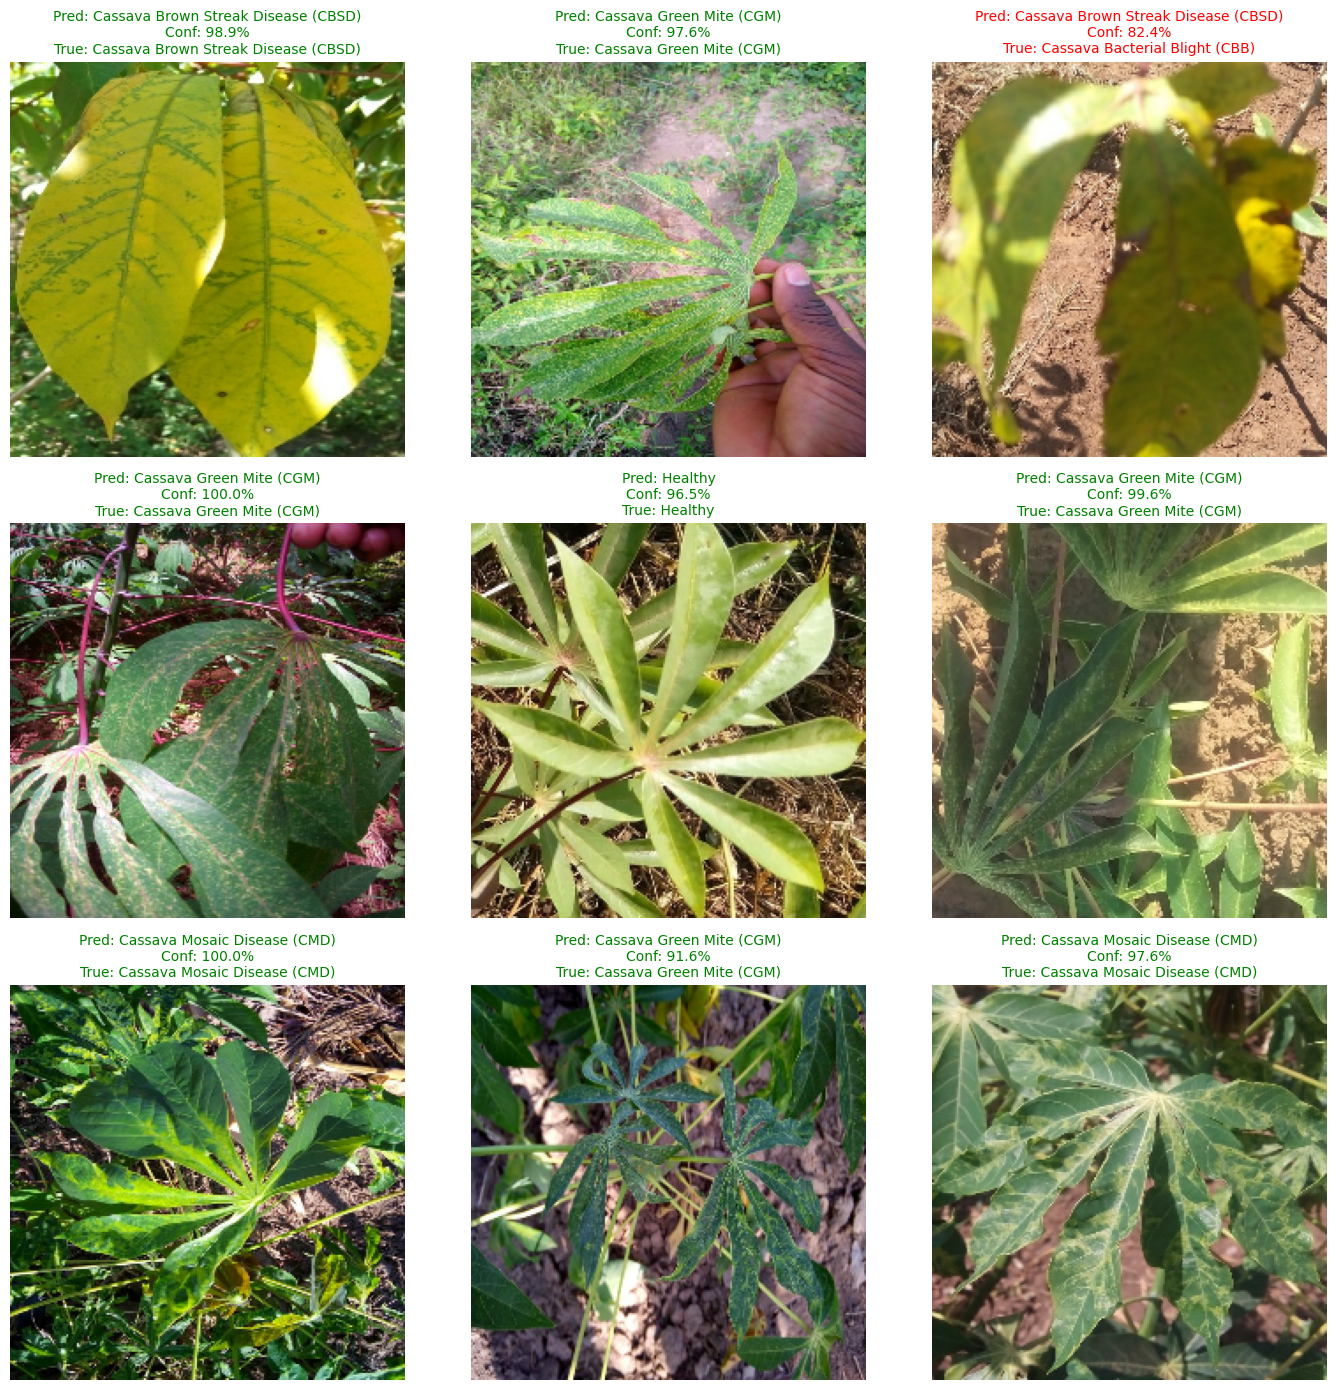

In [6]:
# Load validation split from TensorFlow Datasets
dataset, info = tfds.load('cassava', split='validation', with_info=True)

def preprocess_tfds(data):
    data['image'] = preprocess_image(data['image'])
    return data

# Grab a batch of 9 images
sample_batch = next(iter(dataset.map(preprocess_tfds).batch(9)))
images = sample_batch['image']
true_labels = sample_batch['label'].numpy()

# Run inference
probabilities = classifier(images)
predictions = tf.argmax(probabilities, axis=-1).numpy()
confidences = tf.reduce_max(probabilities, axis=-1).numpy()

# Visualize results
plt.figure(figsize=(14, 14))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])
    pred_name = CLASS_NAMES[predictions[i]]
    true_name = CLASS_NAMES[true_labels[i]]
    color = "green" if predictions[i] == true_labels[i] else "red"

    plt.title(
        f"Pred: {pred_name}\nConf: {confidences[i]*100:.1f}%\nTrue: {true_name}",
        color=color,
        fontsize=10
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

In [4]:
!pip install -q importlib_resources
!rm -rf /root/tensorflow_datasets/cassava

In [7]:
def predict_uploaded_image():
    uploaded = files.upload()

    for filename in uploaded.keys():
        # Load and convert to RGB
        img = Image.open(filename).convert("RGB")
        img_array = np.array(img)

        # Preprocess and add batch dimension: (1, 224, 224, 3)
        processed_img = preprocess_image(img_array)
        input_tensor = tf.expand_dims(processed_img, axis=0)

        # Run CropNet inference
        probs = classifier(input_tensor)[0].numpy()
        pred_idx = np.argmax(probs)
        confidence = probs[pred_idx] * 100

        # Display image and probability breakdown
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

        ax1.imshow(img)
        ax1.set_title(f"Diagnosis: {CLASS_NAMES[pred_idx]}\nConfidence: {confidence:.2f}%", fontweight='bold')
        ax1.axis("off")

        y_pos = np.arange(len(CLASS_NAMES))
        ax2.barh(y_pos, probs * 100, align='center', color='teal')
        ax2.set_yticks(y_pos)
        ax2.set_yticklabels(CLASS_NAMES)
        ax2.invert_yaxis()
        ax2.set_xlabel('Confidence (%)')
        ax2.set_xlim(0, 100)
        ax2.set_title('Class Probabilities')

        plt.tight_layout()
        plt.show()

predict_uploaded_image()

KeyboardInterrupt: 

In [8]:
!pip install -q gradio

import gradio as gr

def diagnose_leaf(input_img):
    if input_img is None:
        return {}

    # Preprocess image to (1, 224, 224, 3) normalized to [0, 1]
    processed = preprocess_image(input_img)
    input_tensor = tf.expand_dims(processed, axis=0)

    # Run CropNet inference
    probs = classifier(input_tensor)[0].numpy()

    # Return dictionary mapping each class label to its probability
    return {CLASS_NAMES[i]: float(probs[i]) for i in range(len(CLASS_NAMES))}

demo = gr.Interface(
    fn=diagnose_leaf,
    inputs=gr.Image(type="numpy", label="Upload Cassava Leaf Photo"),
    outputs=gr.Label(num_top_classes=6, label="CropNet Diagnosis"),
    title="Cassava Leaf Disease Classifier (Google CropNet)",
    description="Upload a photo of a cassava leaf to detect Bacterial Blight, Brown Streak Disease, Green Mite, Mosaic Disease, or Healthy foliage."
)

# share=True creates a public *.gradio.live URL accessible from any phone or browser
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://83a3231d4650be8989.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
